## Task 2 - Precipitation

In [191]:
# Velger hvilke nedbørsdata vi ønsker å hente fra Frost API
parameters_precipitation = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01"
}

# Henter nedbørsdata fra Frost API
url = "https://frost.met.no/observations/v0.jsonld"

response_precipitation = requests.get( # Sender en forespørsel til Frost API
    url,
    params=parameters_precipitation, # Forteller hvilke nedbørsdata vi ønsker
    auth=(client_id, ""),
    timeout=30 # Forespørselen vil time out etter 30 sekunder hvis det ikke kommer noe svar
)

In [192]:
# Gjør om responsen fra Frost API til Python data
data_precipitation = response_precipitation.json()

In [ ]:
# Henter ut datoer og nedbørsmengder
dates_precipitation = []
precipitation_values = []

for day in data_precipitation["data"]:
    for observation in day["observations"]:
        # Bruker måleserien PT6H konsekvent gjennom hele året
        if observation["timeOffset"] == "PT6H":
            dates_precipitation.append(day["referenceTime"])
            precipitation_values.append(observation["value"])

In [194]:
# Lager en DataFrame med datoer og nedbørsmengder
df_precipitation = pd.DataFrame({
    "date": dates_precipitation,
    "precipitation": precipitation_values
})

# Gjør om datoene til datetime-format
df_precipitation["date"] = pd.to_datetime(df_precipitation["date"])

# Sorterer datoene i kronologisk rekkefølge
df_precipitation = df_precipitation.sort_values("date").reset_index(drop=True)

In [195]:
# Kontrollerer om det er noen manglende eller dupliserte datoer i nedbørsdataene
expected_dates = pd.date_range(
    "2025-01-01",
    "2025-12-31",
    tz="UTC"
)

missing_dates = expected_dates.difference(df_precipitation["date"])

print("Missing dates:", len(missing_dates))
print("Duplicate dates:", df_precipitation["date"].duplicated().sum())

Missing dates: 0
Duplicate dates: 0


In [196]:
# Kombinerer temperatur- og nedbørsdataene i én DataFrame
df_combined = pd.merge(
    df_2025[["date", "temperature"]],
    df_precipitation,
    on="date",
)

In [197]:
# Kontrollerer at alle 365 dagene ble med
print("combined observations:", len(df_combined))

combined observations: 365


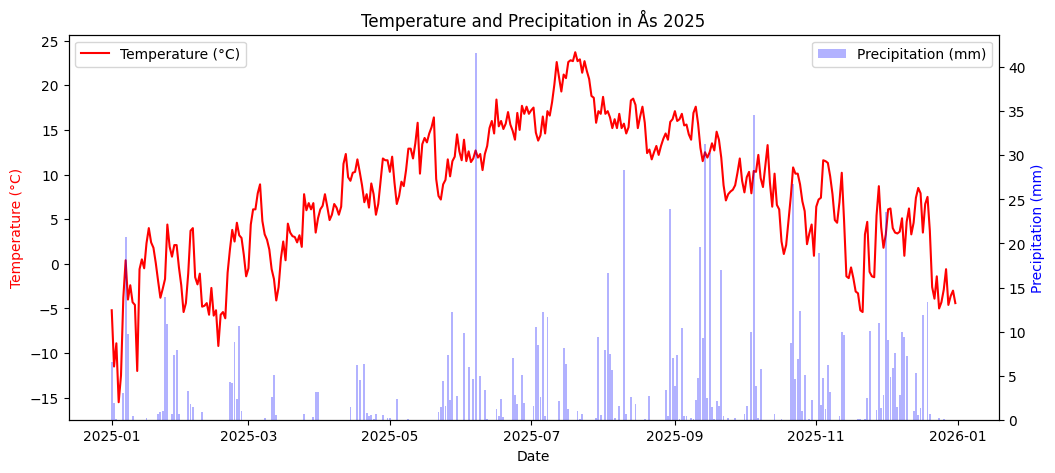

In [198]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df_combined["date"], 
         df_combined["temperature"], 
         color="red", 
         label="Temperature (°C)"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="red")

# Lager en exstra y-akse for nedbør
ax2 = ax1.twinx()

#viser nedbør som søyler
ax2.bar(df_combined["date"], 
        df_combined["precipitation"], 
        color="blue", 
        alpha=0.3,
        label="Precipitation (mm)"
)

ax2.set_ylabel("Precipitation (mm)", color="blue")

# Legger til tittel og forklaring
plt.title("Temperature and Precipitation in Ås 2025")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

# Task 3 - Historical temperature data

Comparison of daily mean air temperatures in Ås for 1925 and 2025. 

In [199]:
from pathlib import Path
import requests
import matplotlib.pyplot as plt
import pandas as pd

client_id = Path("client_id.txt").read_text().strip()

In [200]:
endpoint = "https://frost.met.no/observations/v0.jsonld"

parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01"
}

response = requests.get(
    endpoint, 
    params=parameters, 
    auth=(client_id, ""),
    timeout=30
)

In [201]:
data = response.json()

In [202]:
print(len(data["data"]))

365


In [203]:
dates_1925 = []
temperatures_1925 = []

for day in data["data"]:
    date = day["referenceTime"]
    temperature = day["observations"][0]["value"]

    dates_1925.append(date)
    temperatures_1925.append(temperature)

print(len(dates_1925), len(temperatures_1925))

365 365


In [204]:
# Lager en DataFrame med datoer og temperaturerfor 1925
df_1925 = pd.DataFrame({
    "date": dates_1925,
    "temperature": temperatures_1925
}) 

# Gjør om dato-kolonnen til datetime-format
df_1925["date"] = pd.to_datetime(df_1925["date"])

In [205]:
parameters_2025 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01"
}   

response_2025 = requests.get(
    endpoint, 
    params=parameters_2025, 
    auth=(client_id, ""),
    timeout=30
)

In [206]:
data_2025 = response_2025.json()

print(len(data_2025["data"]))

365


In [207]:
# Lager lister for datoer og temperaturer fra 2025
dates_2025 = []
temperatures_2025 = []

# Går gjennom målingene og lagrer dato og temperatur i listene
for day in data_2025["data"]:
    date = day["referenceTime"]
    temperature = day["observations"][0]["value"]

    dates_2025.append(date)
    temperatures_2025.append(temperature)

print(len(dates_2025), len(temperatures_2025))

365 365


In [208]:
# Lager en DataFrame med datoer og temperaturer for 2025
df_2025 = pd.DataFrame({
    "date": dates_2025,
    "temperature": temperatures_2025
})

# Gjør om dato-kolonnen til datetime-format
df_2025["date"] = pd.to_datetime(df_2025["date"])


In [209]:
# Kontrollerer om det mangler noen datoer i 1925-dataene
all_dates_1925 = pd.date_range("1925-01-01", "1925-12-31", tz="UTC")

missing_1925 = all_dates_1925.difference(df_1925["date"])

print(missing_1925)

DatetimeIndex([], dtype='datetime64[ns, UTC]', freq='D')


In [210]:
# Kontrollerer om det mangler noen datoer i 2025-dataene
all_dates_2025 = pd.date_range("2025-01-01", "2025-12-31", tz="UTC")

missing_2025 = all_dates_2025.difference(df_2025["date"])

print(missing_2025)

DatetimeIndex([], dtype='datetime64[ns, UTC]', freq='D')


In [211]:
# Sammenligner temperaturstatistikk for 1925 og 2025
statistics= pd.DataFrame({
    "1925": [
        df_1925["temperature"].mean(),
        df_1925["temperature"].median(),
        df_1925["temperature"].min(),
        df_1925["temperature"].max()
    ],
    "2025": [
        df_2025["temperature"].mean(),
        df_2025["temperature"].median(),
        df_2025["temperature"].min(),
        df_2025["temperature"].max()
    ]
}, index=["mean", "median", "min", "max"])

print(statistics.round(2))

         1925   2025
mean     5.28   7.87
median   5.30   8.30
min    -20.70 -15.50
max     24.30  23.70


In [212]:
# Finner hvilken dag i året hver temperaturmåling tilhører
df_1925["day_of_year"] = df_1925["date"].dt.dayofyear
df_2025["day_of_year"] = df_2025["date"].dt.dayofyear


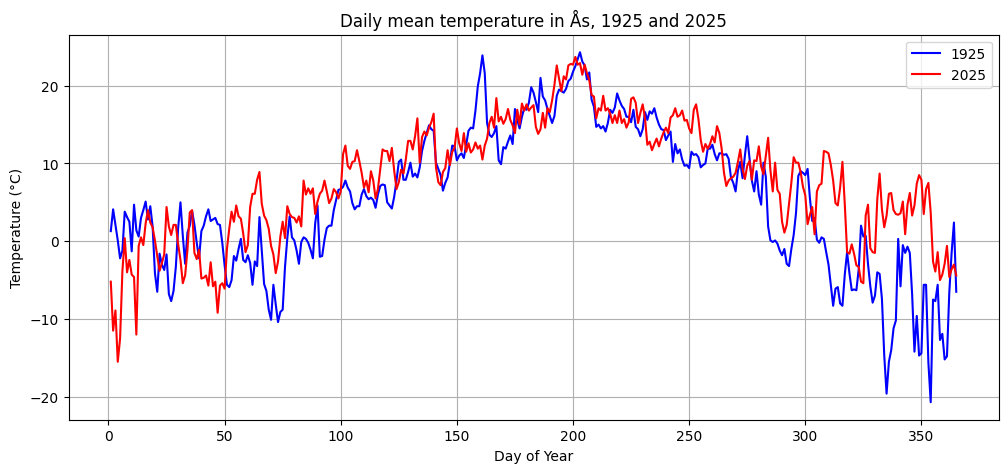

In [213]:
# Lager en graf som sammenligner temperaturene for 1925 og 2025
plt.figure(figsize=(12, 5))

plt.plot(df_1925["day_of_year"], df_1925["temperature"], label="1925", color="blue")
plt.plot(df_2025["day_of_year"], df_2025["temperature"], label="2025", color="red")

plt.xlabel("Day of Year")
plt.ylabel("Temperature (°C)")
plt.title("Daily mean temperature in Ås, 1925 and 2025")

plt.legend()
plt.grid(True)
plt.show()

The average daily temperatrue was 5.28°C in 1925 and 7.87°C in 2025, a difference of 2.59°C. The minimum daily mean teperature was also higher in 2025, while the maximum daily mean temperature was a bit higher i 1925.

## Task 4 - Heatwaves in Ås 2025

In [214]:
# Henter daglige maksimumstemperaturer for Ås i 2025 fra Frost API
parameters_max_2025 = {
    "sources": "SN17850",
    "elements": "max(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01"
}   

response_max_2025 = requests.get(
    endpoint, 
    params=parameters_max_2025, 
    auth=(client_id, ""),
    timeout=30
)

In [215]:
data_max_2025 = response_max_2025.json()

print(len(data_max_2025["data"]))

365


In [216]:
# Henter ut datoer og maksimumstemperaturer fra målingene
dates_max_2025 = []
temperatures_max_2025 = []

for day in data_max_2025["data"]:
    date = day["referenceTime"]
    temperature = day["observations"][0]["value"]

    dates_max_2025.append(date)
    temperatures_max_2025.append(temperature)

print(len(dates_max_2025), len(temperatures_max_2025))

365 365


In [217]:
# Lager en DataFrame med daglige maksimumstemperaturer for 2025
df_max_2025 = pd.DataFrame({
    "date": dates_max_2025,
    "temperature": temperatures_max_2025
})

# Gjør om dato-kolonnen til datetime-format
df_max_2025["date"] = pd.to_datetime(df_max_2025["date"])

# Sorterer datoene i kronologisk rekkefølge
df_max_2025 = df_max_2025.sort_values("date").reset_index(drop=True)

In [218]:
# Kontroller om det mangler noen datoer i 2025
all_dates = pd.date_range("2025-01-01", "2025-12-31", tz="UTC")

missing_dates = all_dates.difference(df_max_2025["date"])

print(missing_dates)

DatetimeIndex([], dtype='datetime64[ns, UTC]', freq='D')


In [219]:
# Sjekker om maksimumstemperaturen er minst 27 grader
df_max_2025["hot_day"] = df_max_2025["temperature"] >= 27

In [220]:
# Oppretter variabler for å telle varmedager og lagre hetebølger
consecutive_days = 0
start_date = None
previous_date = None
heatwaves = []

# Går igjennom dagene og teller sammenhengende dager med minst 27 grader
for index, row in df_max_2025.iterrows():
    if row["hot_day"]:
        consecutive_days += 1

        if consecutive_days == 1:
            start_date = row["date"]

        previous_date = row["date"]

    # Registrerer hetebølgen hvis den varer i minst 5 dager
    else: 
        if consecutive_days >= 5:
            heatwaves.append((start_date, previous_date, consecutive_days))

        consecutive_days = 0

# Sjekker om en hetebølge fortsetter helt til siste dag
if consecutive_days >= 5:
    heatwaves.append((start_date, previous_date, consecutive_days))

for start, end, days in heatwaves:
    print(f"Heatwave: {start.date()} to {end.date()} ({days} days)")

Heatwave: 2025-07-16 to 2025-07-20 (5 days)
